In [1]:
import numpy as np
import pandas as pd
import matplotlib as mp

In [9]:
import os
import glob
import csv
import pandas as pd

def netejar_dataset(filepath):
    filename = os.path.basename(filepath)
    any_data = ''.join(filter(str.isdigit, filename))
    
    registres = []
    seccio_actual = "Barcelona"
    
    with open(filepath, 'r', encoding='utf-8', errors='ignore') as f:
        reader = csv.reader(f)
        
        for row in reader:
            if not row or len(row) < 19:
                continue
                
            codi = row[0].strip()
            nom = row[1].strip()
            preu_m2_total_str = row[18].strip()
            
            # Detectar canvis de secció per la segona columna
            if nom == "Districtes municipals":
                seccio_actual = "Districte"
                continue
            elif nom == "Barris":
                seccio_actual = "Barri"
                continue

            # Fila general de Barcelona
            if nom == "Barcelona*":
                registres.append({
                    'Any': any_data,
                    'Tipus': 'Ciutat',
                    'Codi': '0',
                    'Nom': 'Barcelona',
                    'Preu_m2_Total': netejar_numero(preu_m2_total_str)
                })
            # Entrades amb codi numèric (Districtes 1-10 / Barris 1-73)
            elif codi.isdigit():
                registres.append({
                    'Any': any_data,
                    'Tipus': seccio_actual,
                    'Codi': codi,
                    'Nom': nom,
                    'Preu_m2_Total': netejar_numero(preu_m2_total_str)
                })
                
    return pd.DataFrame(registres)

def netejar_numero(val_str):
    if not val_str or val_str in ['-', '..', '']:
        return None
    try:
        val_clean = val_str.replace('.', '').replace(',', '.')
        return float(val_clean)
    except ValueError:
        return None

if __name__ == '__main__':
    ruta_datasets = os.path.join("datasets", "BCN_acumulat_*.csv")
    fitxers_csv = glob.glob(ruta_datasets)
    
    dfs = []
    for fitxer in fitxers_csv:
        df_net = netejar_dataset(fitxer)
        dfs.append(df_net)
        
    if dfs:
        df_final = pd.concat(dfs, ignore_index=True)
        fitxer_sortida = "dades_preu_m2_netes.csv"
        df_final.to_csv(fitxer_sortida, index=False, encoding='utf-8-sig')
        print(f"Dataset corregit i guardat a '{fitxer_sortida}'.")

Dataset corregit i guardat a 'dades_preu_m2_netes.csv'.


In [10]:
import os
import csv
import pandas as pd

def processar_lloguer(filepath):
    # Llista per identificar districtes
    districtes_llista = [
        "Ciutat Vella", "Eixample", "Sants-Montjuc", "Sants-Montjuïc", "Les Corts", 
        "Sarri-Sant Gervasi", "Sarrià-Sant Gervasi", "Grcia", "Gràcia", 
        "Horta-Guinard", "Horta-Guinardó", "Nou Barris", "Sant Andreu (Distrito)", 
        "Sant Mart", "Sant Martí"
    ]
    
    # Diccionari per a corregir els accents i caràcters mal codificats
    correccio_noms = {
        "Barcelona": "Barcelona",
        "Ciutat Vella": "Ciutat Vella",
        "Eixample": "Eixample",
        "Sants-Montjuc": "Sants-Montjuïc",
        "Sants-Montjuïc": "Sants-Montjuïc",
        "Les Corts": "Les Corts",
        "Sarri-Sant Gervasi": "Sarrià-Sant Gervasi",
        "Sarrià-Sant Gervasi": "Sarrià-Sant Gervasi",
        "Grcia": "Gràcia",
        "Gràcia": "Gràcia",
        "Horta-Guinard": "Horta-Guinardó",
        "Horta-Guinardó": "Horta-Guinardó",
        "Nou Barris": "Nou Barris",
        "Sant Andreu (Distrito)": "Sant Andreu",
        "Sant Mart": "Sant Martí",
        "Sant Martí": "Sant Martí",
        "el Barri Gtic": "el Barri Gòtic",
        "la Sagrada Famlia": "la Sagrada Família",
        "el Poble Sec - AEI Parc Montjuc": "el Poble Sec - Parc Montjuïc",
        "la Marina del Prat Vermell - AEI Zona Franca": "la Marina del Prat Vermell - Zona Franca",
        "Sarri": "Sarrià",
        "el Putxet i el Farr": "el Putxet i el Farró",
        "la Vila de Grcia": "la Vila de Gràcia",
        "el Camp d'en Grassot i Grcia Nova": "el Camp d'en Grassot i Gràcia Nova",
        "el Baix Guinard": "el Baix Guinardó",
        "Can Bar": "Can Baró",
        "el Guinard": "el Guinardó",
        "Sant Gens dels Agudells": "Sant Genís dels Agudells",
        "el Tur de la Peira": "el Turó de la Peira",
        "Torre Bar": "Torre Baró",
        "Bar de Viver": "Baró de Viver",
        "Sant Andreu (Barrio)": "Sant Andreu",
        "el Congrs i els Indians": "el Congrés i els Indians",
        "la Vila Olmpica del Poblenou": "la Vila Olímpica del Poblenou",
        "Diagonal Mar i el Front Martim del Poblenou": "Diagonal Mar i el Front Marítim del Poblenou",
        "el Bess i el Maresme": "el Besòs i el Maresme",
        "Provenals del Poblenou": "Provençals del Poblenou",
        "Sant Mart de Provenals": "Sant Martí de Provençals"
    }

    registres = []
    
    with open(filepath, 'r', encoding='utf-8', errors='ignore') as f:
        reader = csv.reader(f, delimiter=';')
        header = [h.strip() for h in next(reader)]
        
        # Filtrem exclusivament els anys de 2023 a 2025
        anys_desitjats = ['2023', '2024', '2025']
        indices_anys = {yr: header.index(yr) for yr in anys_desitjats if yr in header}
        
        for row in reader:
            if not row:
                continue
                
            raw_nom = row[0].strip()
            nom_net = correccio_noms.get(raw_nom, raw_nom)
            
            # Determinar el Tipus (Ciutat, Districte o Barri)
            if raw_nom == "Barcelona":
                tipus = "Ciutat"
            elif raw_nom in districtes_llista:
                tipus = "Districte"
            else:
                tipus = "Barri"
                
            # Extreure la informació dels anys 2023, 2024 i 2025
            for any_val, idx in indices_anys.items():
                val_str = row[idx].strip() if idx < len(row) else ""
                preu_lloguer_m2 = netejar_numero(val_str)
                
                registres.append({
                    'Any': any_val,
                    'Tipus': tipus,
                    'Nom': nom_net,
                    'Preu_Lloguer_m2': preu_lloguer_m2
                })
                
    return pd.DataFrame(registres)

def netejar_numero(val_str):
    """Converteix cadenes estil '16,10' a flotants de Python: 16.10"""
    if not val_str or val_str in ['-', '..', '']:
        return None
    try:
        val_clean = val_str.replace('.', '').replace(',', '.')
        return float(val_clean)
    except ValueError:
        return None

if __name__ == '__main__':
    # Ruta del fitxer original
    fitxer_entrada = os.path.join("datasets", "datos_alquiler.csv")
    if not os.path.exists(fitxer_entrada):
        fitxer_entrada = "datos_alquiler.csv"  # Per si està a la carpeta arrel
        
    print(f"Processant: {fitxer_entrada}...")
    df_lloguer = processar_lloguer(fitxer_entrada)
    
    # Guardar el fitxer netejat
    fitxer_sortida = "lloguer_2023_2025_net.csv"
    df_lloguer.to_csv(fitxer_sortida, index=False, encoding='utf-8-sig')
    
    print(f"\nProcés finalitzat amb èxit! Guardat a '{fitxer_sortida}'.\n")
    print(df_lloguer.head(15))

Processant: datasets\datos_alquiler.csv...

Procés finalitzat amb èxit! Guardat a 'lloguer_2023_2025_net.csv'.

     Any      Tipus             Nom  Preu_Lloguer_m2
0   2023     Ciutat       Barcelona            16.10
1   2024     Ciutat       Barcelona            16.13
2   2025     Ciutat       Barcelona            16.67
3   2023  Districte    Ciutat Vella            16.66
4   2024  Districte    Ciutat Vella            16.60
5   2025  Districte    Ciutat Vella            18.13
6   2023      Barri        el Raval            15.89
7   2024      Barri        el Raval            15.94
8   2025      Barri        el Raval            16.61
9   2023      Barri  el Barri Gòtic            16.44
10  2024      Barri  el Barri Gòtic            16.22
11  2025      Barri  el Barri Gòtic            16.49
12  2023      Barri  la Barceloneta            18.98
13  2024      Barri  la Barceloneta            19.97
14  2025      Barri  la Barceloneta            22.70


C:\Users\nilmo\AppData\Local\Temp\ipykernel_27976\2498119763.py:92: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  inc_c.rename(columns={'Preu_m2_Total': 'Increment_%'}, inplace=True)
C:\Users\nilmo\AppData\Local\Temp\ipykernel_27976\2498119763.py:98: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  inc_l.rename(columns={'Preu_Lloguer_m2': 'Increment_%'}, inplace=True)


Gràfics d'evolució generats i guardats a 'datasets\grafic_diferencia_anys.png'.


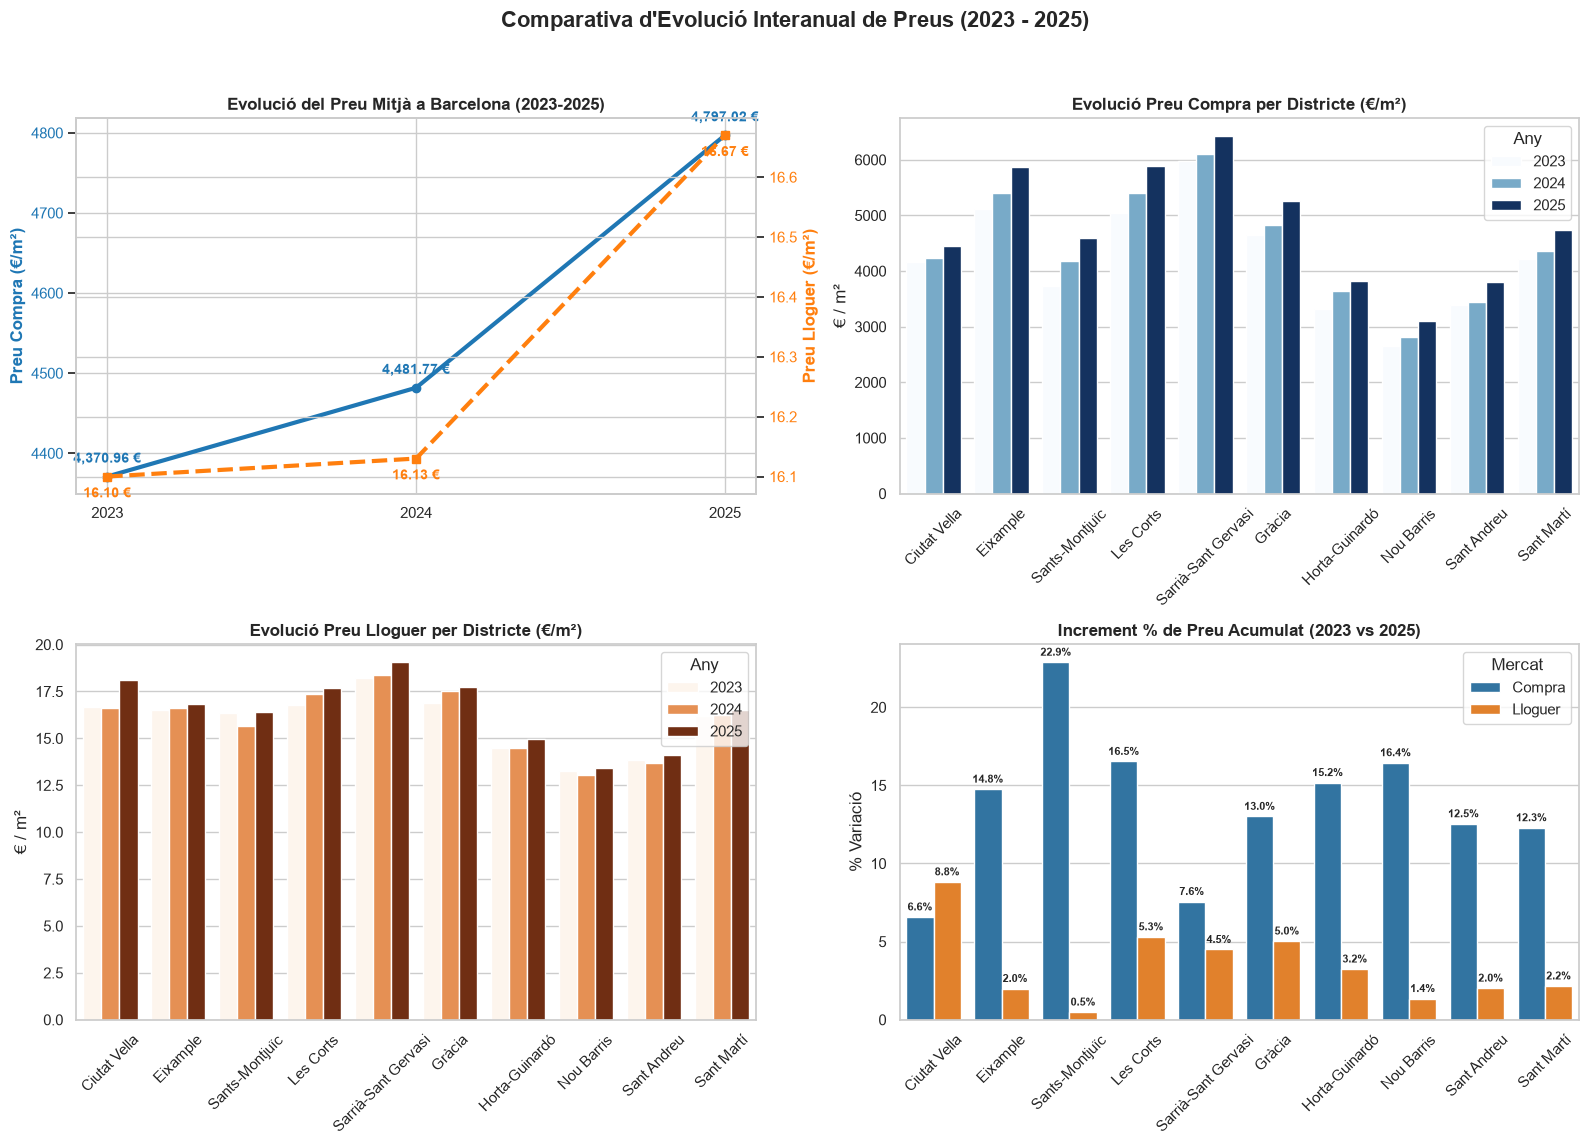

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo visual
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 10, 'figure.autolayout': True})

def carregar_dades():
    ruta_datasets = "datasets"
    f_compra = os.path.join(ruta_datasets, "dades_preu_m2_netes.csv")
    f_lloguer = os.path.join(ruta_datasets, "lloguer_2023_2025_net.csv")
    
    if not os.path.exists(f_compra):
        f_compra = "dades_preu_m2_netes.csv"
        f_lloguer = "lloguer_2023_2025_net.csv"

    if not os.path.exists(f_compra) or not os.path.exists(f_lloguer):
        print("Error: No s'han trobat els fitxers a la carpeta 'datasets'.")
        return None, None

    df_compra = pd.read_csv(f_compra)
    df_lloguer = pd.read_csv(f_lloguer)
    return df_compra, df_lloguer

def generar_graficos_diferencia_anys(df_compra, df_lloguer):
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle('Comparativa d\'Evolució Interanual de Preus (2023 - 2025)', fontsize=16, fontweight='bold')

    # -------------------------------------------------------------
    # 1. Evolución Media en Barcelona Ciutat
    # -------------------------------------------------------------
    df_bcn_c = df_compra[df_compra['Tipus'] == 'Ciutat'].sort_values('Any')
    df_bcn_l = df_lloguer[df_lloguer['Tipus'] == 'Ciutat'].sort_values('Any')

    ax1 = axes[0, 0]
    color_c = '#1f77b4'
    color_l = '#ff7f0e'

    ax1.plot(df_bcn_c['Any'].astype(str), df_bcn_c['Preu_m2_Total'], marker='o', color=color_c, linewidth=3, label='Compra (€/m²)')
    ax1.set_ylabel('Preu Compra (€/m²)', color=color_c, fontweight='bold')
    ax1.tick_params(axis='y', labelcolor=color_c)
    ax1.set_title('Evolució del Preu Mitjà a Barcelona (2023-2025)', fontsize=12, fontweight='bold')

    ax1_sub = ax1.twinx()
    ax1_sub.plot(df_bcn_l['Any'].astype(str), df_bcn_l['Preu_Lloguer_m2'], marker='s', color=color_l, linewidth=3, linestyle='--', label='Lloguer (€/m²)')
    ax1_sub.set_ylabel('Preu Lloguer (€/m²)', color=color_l, fontweight='bold')
    ax1_sub.tick_params(axis='y', labelcolor=color_l)

    for _, row in df_bcn_c.iterrows():
        ax1.annotate(f"{row['Preu_m2_Total']:,.2f} €", (str(row['Any']), row['Preu_m2_Total']), 
                     textcoords="offset points", xytext=(0, 10), ha='center', fontweight='bold', color=color_c)

    for _, row in df_bcn_l.iterrows():
        ax1_sub.annotate(f"{row['Preu_Lloguer_m2']:.2f} €", (str(row['Any']), row['Preu_Lloguer_m2']), 
                         textcoords="offset points", xytext=(0, -15), ha='center', fontweight='bold', color=color_l)

    # -------------------------------------------------------------
    # 2. Precio Compra por Distrito (Colores sin blancos)
    # -------------------------------------------------------------
    df_dist_c = df_compra[df_compra['Tipus'] == 'Districte']
    ax2 = axes[0, 1]
    
    # Paleta con colores oscuros y visibles para 2023, 2024 y 2025
    palette_compra = ['#729ea1', '#386641', '#1a3636']
    sns.barplot(data=df_dist_c, x='